# 2

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#2.(a)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import time
K = 3
N = 6
y_true = np.array([0, 0, 1, 1, 2, 2])
y_pred = np.array([0, 1, 1, 2, 2, 0])
w_initial = np.ones(N) / N

mistakes = (y_true != y_pred)
err_t = np.sum(w_initial[mistakes])

alpha = (np.log((1 - err_t) / err_t)) + np.log(K - 1)

w_unnorm = w_initial * np.exp(alpha * mistakes)
w_updated = w_unnorm / np.sum(w_unnorm)

print("SAMME Example:")
print(f"Initial weights:     {np.round(w_initial, 4)}")
print(f"Predictions:         {y_pred}")
print(f"True Labels:         {y_true}")
print(f"Weighted Error:      {err_t:.4f}")
print(f"Learner Weight (a_t):{alpha:.4f}")
print(f"Updated Weights:     {np.round(w_updated, 4)}")


SAMME Example:
Initial weights:     [0.1667 0.1667 0.1667 0.1667 0.1667 0.1667]
Predictions:         [0 1 1 2 2 0]
True Labels:         [0 0 1 1 2 2]
Weighted Error:      0.5000
Learner Weight (a_t):0.6931
Updated Weights:     [0.1111 0.2222 0.1111 0.2222 0.1111 0.2222]


In [ ]:
#2.(b)
roll = 26017 #M26CSA017
rng = np.random.RandomState(roll)
faces = fetch_olivetti_faces(shuffle=True, random_state=rng)
X = faces.data
y = faces.target
images = faces.images

train_idx = []
val_idx = []
test_idx = []

for i in range(40):
    identity_indices = np.where(y == i)[0]
    rng.shuffle(identity_indices)
    train_idx.extend(identity_indices[:6])
    val_idx.extend(identity_indices[6:8])
    test_idx.extend(identity_indices[8:])

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test_clean, y_test = X[test_idx], y[test_idx]

X_test_masked = X_test_clean.copy()
for i in range(len(X_test_masked)):
    img = X_test_masked[i].reshape(64, 64)
    img[24:40, 24:40] = 0.0
    X_test_masked[i] = img.flatten()

print(f"Train size: {X_train.shape}, Val size: {X_val.shape}, Test size: {X_test_clean.shape}")

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Train size: (240, 4096), Val size: (80, 4096), Test size: (80, 4096)



Model Selection:
Best SAMME parameters (depth, rounds): (3, 100) with Val Acc: 0.4000


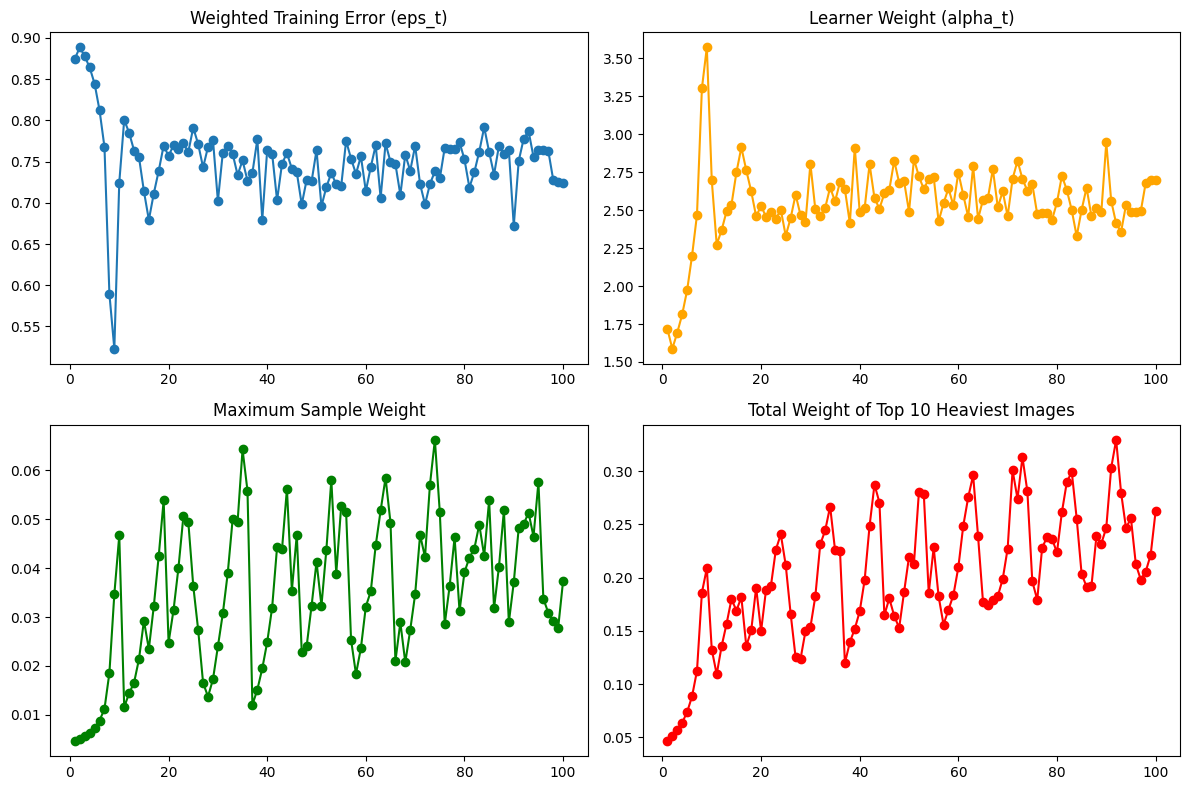

In [ ]:
K = 40
depths = [1, 2, 3, 4]
rounds = [10, 25, 50, 100]

def train_samme(X_tr, y_tr, max_depth, n_rounds):
    N = len(X_tr)
    w = np.ones(N) / N
    models, alphas = [], []

    err_history, alpha_history, max_w_history, top10_w_history = [], [], [], []

    for t in range(n_rounds):
        dt = DecisionTreeClassifier(max_depth=max_depth, random_state=t)
        dt.fit(X_tr, y_tr, sample_weight=w)
        preds = dt.predict(X_tr)

        mistakes = (preds != y_tr)
        err_t = np.sum(w[mistakes])

        if err_t >= (1.0 - 1.0 / K):
            break

        if err_t == 0:
            alpha_t = np.log((1 - 1e-10) / 1e-10) + np.log(K - 1)
        else:
            alpha_t = np.log((1 - err_t) / err_t) + np.log(K - 1)

        w_unnorm = w * np.exp(alpha_t * mistakes)
        w = w_unnorm / np.sum(w_unnorm)

        models.append(dt)
        alphas.append(alpha_t)

        err_history.append(err_t)
        alpha_history.append(alpha_t)
        max_w_history.append(np.max(w))
        top10_w_history.append(np.sum(np.sort(w)[-10:]))

    return models, alphas, w, err_history, alpha_history, max_w_history, top10_w_history

def predict_samme(models, alphas, X_data):

    n_samples = len(X_data)
    scores = np.zeros((n_samples, K))

    for dt, alpha in zip(models, alphas):
        preds = dt.predict(X_data)
        for i in range(n_samples):
            scores[i, preds[i]] += alpha

    final_preds = np.argmax(scores, axis=1)

    confidences = np.max(scores, axis=1) / np.sum(alphas)
    return final_preds, confidences

best_val_acc = -1
best_samme_model = None

for d in depths:
    for r in rounds:
        models, alphas, _, _, _, _, _ = train_samme(X_train, y_train, d, r)
        val_preds, _ = predict_samme(models, alphas, X_val)
        val_acc = np.mean(val_preds == y_val)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_samme_model = (d, r)

print(f"\nModel Selection:")
print(f"Best SAMME parameters (depth, rounds): {best_samme_model} with Val Acc: {best_val_acc:.4f}")

best_d, best_r = best_samme_model
final_models, final_alphas, final_weights, err_hist, alpha_hist, max_w_hist, top10_w_hist = train_samme(X_train, y_train, best_d, best_r)

plt.figure(figsize=(12, 8))
rounds_arr = np.arange(1, len(err_hist) + 1)

plt.subplot(2, 2, 1)
plt.plot(rounds_arr, err_hist, marker='o')
plt.title("Weighted Training Error (eps_t)")

plt.subplot(2, 2, 2)
plt.plot(rounds_arr, alpha_hist, marker='o', color='orange')
plt.title("Learner Weight (alpha_t)")

plt.subplot(2, 2, 3)
plt.plot(rounds_arr, max_w_hist, marker='o', color='green')
plt.title("Maximum Sample Weight")

plt.subplot(2, 2, 4)
plt.plot(rounds_arr, top10_w_hist, marker='o', color='red')
plt.title("Total Weight of Top 10 Heaviest Images")

plt.tight_layout()
plt.show()

In [ ]:
#2.(c)
rounds_c = [25, 50, 100]

for r in rounds_c:

    start_time = time.time()
    bag_models = []
    N = len(X_train)
    for i in range(r):
        boot_idx = np.random.choice(N, size=N, replace=True)
        dt = DecisionTreeClassifier(max_depth=8, random_state=i)
        dt.fit(X_train[boot_idx], y_train[boot_idx])
        bag_models.append(dt)
    bag_time = time.time() - start_time

    bag_train_preds = np.array([m.predict(X_train) for m in bag_models])
    bag_train_maj = [np.bincount(bag_train_preds[:, i]).argmax() for i in range(N)]
    bag_train_acc = np.mean(bag_train_maj == y_train)

    bag_val_preds = np.array([m.predict(X_val) for m in bag_models])
    bag_val_maj = [np.bincount(bag_val_preds[:, i]).argmax() for i in range(len(X_val))]
    bag_val_acc = np.mean(bag_val_maj == y_val)

    bag_test_preds = np.array([m.predict(X_test_clean) for m in bag_models])
    bag_test_maj = [np.bincount(bag_test_preds[:, i]).argmax() for i in range(len(X_test_clean))]
    bag_test_acc = np.mean(bag_test_maj == y_test)

    start_time = time.time()
    b_models, b_alphas, _, _, _, _, _ = train_samme(X_train, y_train, best_d, r)
    boost_time = time.time() - start_time

    boost_tr_p, _ = predict_samme(b_models, b_alphas, X_train)
    boost_v_p, _ = predict_samme(b_models, b_alphas, X_val)
    boost_te_p, _ = predict_samme(b_models, b_alphas, X_test_clean)

    boost_train_acc = np.mean(boost_tr_p == y_train)
    boost_val_acc = np.mean(boost_v_p == y_val)
    boost_test_acc = np.mean(boost_te_p == y_test)

    print(f"Rounds: {r}")
    print(f"  Bagging  | Train: {bag_train_acc:.3f}, Val: {bag_val_acc:.3f}, Test: {bag_test_acc:.3f} | Time: {bag_time:.3f}s")
    print(f"  Boosting | Train: {boost_train_acc:.3f}, Val: {boost_val_acc:.3f}, Test: {boost_test_acc:.3f} | Time: {boost_time:.3f}s")

heaviest_idx = np.argmax(final_weights)
print(f"\nHeaviest Training Image Index: {heaviest_idx}")
print(f"Final Weight: {final_weights[heaviest_idx]:.4f}")

history = [m.predict(X_train[heaviest_idx].reshape(1, -1))[0] == y_train[heaviest_idx] for m in final_models[:25]]
print(f"Prediction History (True/False) first 25 rounds: \n{history}")

Rounds: 25
  Bagging  | Train: 0.512, Val: 0.388, Test: 0.362 | Time: 22.914s
  Boosting | Train: 0.400, Val: 0.150, Test: 0.163 | Time: 11.944s
Rounds: 50
  Bagging  | Train: 0.675, Val: 0.487, Test: 0.400 | Time: 45.236s
  Boosting | Train: 0.713, Val: 0.300, Test: 0.263 | Time: 23.271s
Rounds: 100
  Bagging  | Train: 0.704, Val: 0.487, Test: 0.475 | Time: 91.009s
  Boosting | Train: 0.871, Val: 0.400, Test: 0.300 | Time: 46.559s

Heaviest Training Image Index: 47
Final Weight: 0.0374
Prediction History (True/False) first 25 rounds: 
[np.False_, np.False_, np.True_, np.False_, np.False_, np.False_, np.False_, np.False_, np.False_, np.False_, np.False_, np.False_, np.False_, np.True_, np.False_, np.False_, np.False_, np.False_, np.False_, np.False_, np.False_, np.False_, np.True_, np.False_, np.False_]



Robustness Evaluation:
Bagging (Clean)  - Acc: 0.4750, Mean Conf: 0.1847
Bagging (Masked) - Acc: 0.4250, Mean Conf: 0.1847
Boosting (Clean) - Acc: 0.3000, Mean Conf: 0.1007
Boosting (Masked)- Acc: 0.2625, Mean Conf: 0.1004

Divergence on Masked Test Face Index: 0
True Class: 0
Bagging Pred: 4 (Vote fraction: 0.1300)
Boosting Pred: 0 (Confidence: 0.0992)


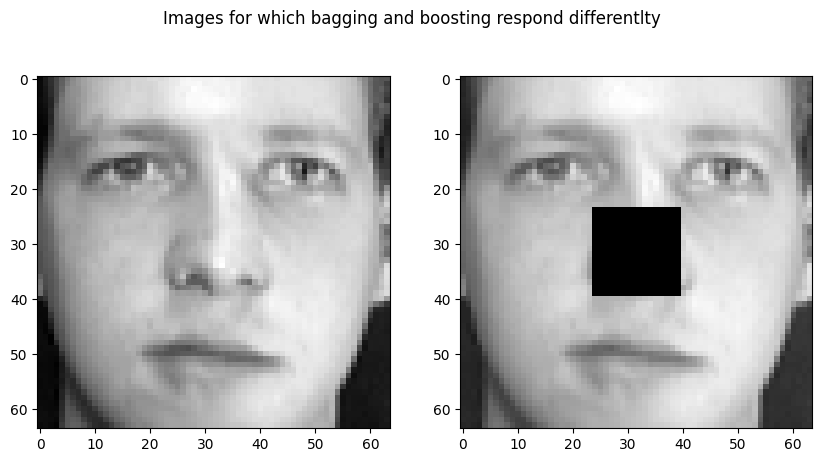

In [ ]:
#2.(d)
bag_mask_preds_raw = np.array([m.predict(X_test_masked) for m in bag_models])
bag_mask_maj = []
bag_mask_conf = []
for i in range(len(X_test_masked)):
    counts = np.bincount(bag_mask_preds_raw[:, i], minlength=K)
    best_class = counts.argmax()
    bag_mask_maj.append(best_class)
    bag_mask_conf.append(counts[best_class] / 100.0)
bag_mask_maj = np.array(bag_mask_maj)

boost_clean_preds, boost_clean_conf = predict_samme(final_models, final_alphas, X_test_clean)
boost_mask_preds, boost_mask_conf = predict_samme(final_models, final_alphas, X_test_masked)

print(f"\nRobustness Evaluation:")

print(f"Bagging (Clean)  - Acc: {bag_test_acc:.4f}, Mean Conf: {np.mean(bag_mask_conf):.4f}")
print(f"Bagging (Masked) - Acc: {np.mean(bag_mask_maj == y_test):.4f}, Mean Conf: {np.mean(bag_mask_conf):.4f}")
print(f"Boosting (Clean) - Acc: {np.mean(boost_clean_preds == y_test):.4f}, Mean Conf: {np.mean(boost_clean_conf):.4f}")
print(f"Boosting (Masked)- Acc: {np.mean(boost_mask_preds == y_test):.4f}, Mean Conf: {np.mean(boost_mask_conf):.4f}")

diverge_idx = np.where(bag_mask_maj != boost_mask_preds)[0]
if len(diverge_idx) > 0:
    idx = diverge_idx[0]
    clean_face = X_test_clean[idx].reshape(64, 64)
    masked_face = X_test_masked[idx].reshape(64, 64)

    true_label = y_test[idx]
    bag_pred = bag_mask_maj[idx]
    boost_pred = boost_mask_preds[idx]
    print(f"\nDivergence on Masked Test Face Index: {idx}")
    print(f"True Class: {y_test[idx]}")
    print(f"Bagging Pred: {bag_mask_maj[idx]} (Vote fraction: {bag_mask_conf[idx]:.4f})")
    print(f"Boosting Pred: {boost_mask_preds[idx]} (Confidence: {boost_mask_conf[idx]:.4f})")

    fig, axes = plt.subplots(1,2, figsize=(10,5))
    fig.suptitle(f"Images for which bagging and boosting respond differentlty")
    axes[0].imshow(clean_face, cmap="gray")
    axes[1].imshow(masked_face, cmap="gray")
    plt.show()
else:
    print(f"No diverging predictions found between Bagging and Boosting on the masked dataset.")

In [ ]:
import numpy as np

try:
    # Prepare structured dictionary elements for each section
    results_dict = {}

    # --- Section 2.(a) ---
    results_dict['2_a_y_true'] = y_true if 'y_true' in globals() else None
    results_dict['2_a_y_pred'] = y_pred if 'y_pred' in globals() else None
    results_dict['2_a_w_initial'] = w_initial if 'w_initial' in globals() else None
    results_dict['2_a_w_updated'] = w_updated if 'w_updated' in globals() else None

    # --- Section 2.(b) ---
    results_dict['2_b_X_train'] = X_train if 'X_train' in globals() else None
    results_dict['2_b_y_train'] = y_train if 'y_train' in globals() else None
    results_dict['2_b_X_val'] = X_val if 'X_val' in globals() else None
    results_dict['2_b_y_val'] = y_val if 'y_val' in globals() else None
    results_dict['2_b_X_test_clean'] = X_test_clean if 'X_test_clean' in globals() else None
    results_dict['2_b_X_test_masked'] = X_test_masked if 'X_test_masked' in globals() else None
    results_dict['2_b_y_test'] = y_test if 'y_test' in globals() else None

    # --- Section 2.(c) ---
    results_dict['2_c_best_samme_model'] = np.array(best_samme_model) if 'best_samme_model' in globals() else None
    results_dict['2_c_err_hist'] = np.array(err_hist) if 'err_hist' in globals() else None
    results_dict['2_c_alpha_hist'] = np.array(alpha_hist) if 'alpha_hist' in globals() else None
    results_dict['2_c_max_w_hist'] = np.array(max_w_hist) if 'max_w_hist' in globals() else None
    results_dict['2_c_top10_w_hist'] = np.array(top10_w_hist) if 'top10_w_hist' in globals() else None
    results_dict['2_c_final_weights'] = final_weights if 'final_weights' in globals() else None
    results_dict['2_c_bag_test_acc'] = bag_test_acc if 'bag_test_acc' in globals() else None
    results_dict['2_c_boost_test_acc'] = boost_test_acc if 'boost_test_acc' in globals() else None

    # --- Section 2.(d) ---
    results_dict['2_d_bag_mask_acc'] = np.mean(bag_mask_maj == y_test) if 'bag_mask_maj' in globals() else None
    results_dict['2_d_boost_mask_acc'] = np.mean(boost_mask_preds == y_test) if 'boost_mask_preds' in globals() else None

    # Save structured dictionary to resultsQ2.npz
    np.savez('resultsQ2.npz', **results_dict)
    print("Results successfully structured and saved to 'resultsQ2.npz'.")
except Exception as e:
    print(f"An error occurred while saving: {e}")

Results successfully structured and saved to 'resultsQ2.npz'.
